# Entrenamiento de modelos

Torneo de 6 modelos para predecir `SalePrice`: regresiones regularizadas (Ridge, Lasso, ElasticNet), ensambles (Random Forest, Gradient Boosting) y una red neuronal artificial (MLP). Cada modelo se optimiza con validación cruzada `KFold=10` y se compara contra el conjunto de validación con RMSE real y RMSE normalizado al rango.

**Control de fuga de datos:** el entrenamiento parte de los datos crudos, y el pipeline de preprocesamiento se reajusta dentro de cada fold junto con el modelo. Por eso no se usan los CSV de `data/processed/`, cuyo pipeline ya vio todas las filas de entrenamiento.

## 1. Importación de librerías

Se cargan las herramientas de `scikit-learn` para validación cruzada, búsqueda de hiperparámetros, modelos y métricas.

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.ticker import FuncFormatter
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from ejercicio_clases.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR

2026-11-10 19:44:38.896 | INFO     | ejercicio_clases.config:<module>:12 - PROJ_ROOT path is: C:\Users\aillu\OneDrive - Empresa Eléctrica de Guatemala, S.A. (EEGSA)\Mis Documentos\Universidad\4. Trimestre\1 - PRODUCT DEVELOPMENT\3. Semana\Ejercicio en Clases\ejercicio_clases


## 2. Parámetros y carga de datos

Se definen los parámetros del torneo y se cargan `train.csv`, la lista `MODEL_FEATURES` y el pipeline de preprocesamiento.

In [2]:
# Rutas de las fuentes de información (cambiar aquí si los datos se mueven)
TRAIN_FILE = RAW_DATA_DIR / "train.csv"
CONFIG_FILE = PROJ_ROOT / "pipeline_config.yaml"
PIPELINE_FILE = MODELS_DIR / "pipeline_preprocesamiento.joblib"

TARGET = "SalePrice"
TAMANO_VALIDACION = 0.20
SEMILLA = 42
N_FOLDS = 10
N_CONFIGURACIONES = 20

with open(CONFIG_FILE, encoding="utf-8") as archivo:
    MODEL_FEATURES = yaml.safe_load(archivo)["MODEL_FEATURES"]

df_train = pd.read_csv(TRAIN_FILE, index_col="Id")
pipeline_guardado = joblib.load(PIPELINE_FILE)

print(f"Train: {df_train.shape} | Features: {len(MODEL_FEATURES)} | Pasos de FE: {len(pipeline_guardado.steps)}")

Train: (1460, 80) | Features: 30 | Pasos de FE: 9


## 3. División de datos

Se reproduce la división del notebook de preprocesamiento (80/20, misma semilla) y se eliminan los 2 registros atípicos solo del conjunto de entrenamiento. La celda confirma que ambos conjuntos contienen exactamente los mismos registros que los CSV procesados, de modo que validación sigue siendo un conjunto no usado para ajustar nada en este notebook.

In [3]:
X = df_train[MODEL_FEATURES]
y = np.log1p(df_train[TARGET])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TAMANO_VALIDACION, random_state=SEMILLA
)

ids_atipicos = df_train[(df_train["GrLivArea"] > 4000) & (df_train[TARGET] < 300000)].index
X_train = X_train.drop(ids_atipicos, errors="ignore")
y_train = y_train.drop(ids_atipicos, errors="ignore")

# Comprobación de que la división coincide con la del notebook de preprocesamiento
ids_train = pd.read_csv(PROCESSED_DATA_DIR / "train_procesado.csv", usecols=["Id"])["Id"]
ids_val = pd.read_csv(PROCESSED_DATA_DIR / "validacion_procesado.csv", usecols=["Id"])["Id"]
assert X_train.index.equals(pd.Index(ids_train)) and X_val.index.equals(pd.Index(ids_val))
assert X_train.index.intersection(X_val.index).empty

print(f"Entrenamiento: {X_train.shape} | Validación: {X_val.shape}")

Entrenamiento: (1166, 30) | Validación: (292, 30)


## 4. Pipeline de preprocesamiento sin ajustar

`clone` copia la configuración del pipeline guardado y descarta todo lo aprendido (medianas, límites, codificación, escalas). Cada candidato se forma con este pipeline sin ajustar y un modelo, de modo que en cada fold el preprocesamiento aprende solo de las filas de entrenamiento de ese fold.

In [4]:
pipeline_fe = clone(pipeline_guardado)


def crear_candidato(modelo):
    return Pipeline([("fe", clone(pipeline_fe)), ("modelo", modelo)])


pipeline_fe.steps[0]

('indicador_faltantes',
 AddMissingIndicator(variables=['LotFrontage', 'GarageYrBlt', 'MasVnrArea']))

## 5. Modelos y espacios de búsqueda

Se definen los 6 modelos y sus hiperparámetros. Para limitar el sobreajuste:

- **Regresiones:** regularización L2, L1 o combinada, según el modelo.
- **Random Forest:** límites de profundidad, tamaño de hoja y variables por división.
- **Gradient Boosting:** tasa de aprendizaje baja, árboles poco profundos, submuestreo y parada temprana.
- **Red neuronal:** regularización L2 y parada temprana. El target se escala dentro de cada ajuste con `TransformedTargetRegressor`.

In [5]:
catalogo = {
    "Ridge": (
        Ridge(),
        {"modelo__alpha": loguniform(1e-3, 1e3)},
    ),
    "Lasso": (
        Lasso(max_iter=20000, random_state=SEMILLA),
        {"modelo__alpha": loguniform(1e-5, 1)},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=20000, random_state=SEMILLA),
        {"modelo__alpha": loguniform(1e-5, 1), "modelo__l1_ratio": uniform(0.05, 0.90)},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=SEMILLA),
        {
            "modelo__max_depth": randint(4, 21),
            "modelo__min_samples_leaf": randint(1, 11),
            "modelo__max_features": uniform(0.2, 0.6),
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(
            n_estimators=2000, n_iter_no_change=20, validation_fraction=0.1, random_state=SEMILLA
        ),
        {
            "modelo__learning_rate": loguniform(0.005, 0.2),
            "modelo__max_depth": randint(2, 5),
            "modelo__min_samples_leaf": randint(1, 21),
            "modelo__subsample": uniform(0.6, 0.4),
            "modelo__max_features": uniform(0.3, 0.7),
        },
    ),
    "Red neuronal (MLP)": (
        TransformedTargetRegressor(
            regressor=MLPRegressor(
                max_iter=2000, early_stopping=True, n_iter_no_change=30, random_state=SEMILLA
            ),
            transformer=StandardScaler(),
        ),
        {
            "modelo__regressor__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
            "modelo__regressor__alpha": loguniform(1e-4, 10),
            "modelo__regressor__learning_rate_init": loguniform(1e-4, 1e-2),
        },
    ),
}

print(f"Modelos en el torneo: {list(catalogo)}")

Modelos en el torneo: ['Ridge', 'Lasso', 'ElasticNet', 'Random Forest', 'Gradient Boosting', 'Red neuronal (MLP)']


## 6. Búsqueda de hiperparámetros con validación cruzada

Para cada modelo, `RandomizedSearchCV` prueba 20 configuraciones con `KFold=10` y selecciona la de menor RMSE sobre el target en escala logarítmica. El mejor candidato se reentrena con todo el conjunto de entrenamiento. El conjunto de validación no participa en este paso.

In [6]:
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)

busquedas = {}
for nombre, (modelo, espacio) in catalogo.items():
    inicio = time.perf_counter()
    busqueda = RandomizedSearchCV(
        crear_candidato(modelo),
        param_distributions=espacio,
        n_iter=N_CONFIGURACIONES,
        cv=kfold,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        random_state=SEMILLA,
        n_jobs=-1,
        error_score="raise",
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f"{nombre}: RMSE log CV = {-busqueda.best_score_:.4f} | {time.perf_counter() - inicio:.0f} s")
    print(f"  Mejores hiperparámetros: {busqueda.best_params_}")

Ridge: RMSE log CV = 0.1296 | 27 s
  Mejores hiperparámetros: {'modelo__alpha': np.float64(24.658329458549105)}


Lasso: RMSE log CV = 0.1296 | 17 s
  Mejores hiperparámetros: {'modelo__alpha': np.float64(0.0007459343285726547)}


ElasticNet: RMSE log CV = 0.1296 | 23 s
  Mejores hiperparámetros: {'modelo__alpha': np.float64(0.009163741808778781), 'modelo__l1_ratio': np.float64(0.09180537144799795)}


Random Forest: RMSE log CV = 0.1323 | 44 s
  Mejores hiperparámetros: {'modelo__max_depth': 17, 'modelo__max_features': np.float64(0.4346363645439445), 'modelo__min_samples_leaf': 2}


Gradient Boosting: RMSE log CV = 0.1262 | 43 s
  Mejores hiperparámetros: {'modelo__learning_rate': np.float64(0.09641346525108922), 'modelo__max_depth': 2, 'modelo__max_features': np.float64(0.31094548471883576), 'modelo__min_samples_leaf': 9, 'modelo__subsample': np.float64(0.908897907718663)}


Red neuronal (MLP): RMSE log CV = 0.1282 | 68 s
  Mejores hiperparámetros: {'modelo__regressor__alpha': np.float64(4.929053648241672), 'modelo__regressor__hidden_layer_sizes': (64,), 'modelo__regressor__learning_rate_init': np.float64(0.0002310201887845295)}


## 7. Diagnóstico de sobreajuste en validación cruzada

Se compara, para la mejor configuración de cada modelo, el RMSE logarítmico en las filas de entrenamiento y en las filas retenidas de cada fold. Una brecha grande indica que el modelo memoriza los datos en lugar de generalizar.

In [7]:
filas = []
for nombre, busqueda in busquedas.items():
    i = busqueda.best_index_
    resultados = busqueda.cv_results_
    filas.append({
        "modelo": nombre,
        "rmse_log_train_cv": -resultados["mean_train_score"][i],
        "rmse_log_cv": -resultados["mean_test_score"][i],
        "desv_folds": resultados["std_test_score"][i],
    })

df_cv = pd.DataFrame(filas).set_index("modelo")
df_cv["brecha_cv"] = df_cv["rmse_log_cv"] - df_cv["rmse_log_train_cv"]
df_cv.sort_values("rmse_log_cv").round(4)

,rmse_log_train_cv,rmse_log_cv,desv_folds,brecha_cv
modelo,,,,
Gradient Boosting,0.1102,0.1262,0.0170,0.0160
Red neuronal (MLP),0.1152,0.1282,0.0138,0.0130
ElasticNet,0.1259,0.1296,0.0132,0.0037
Ridge,0.1259,0.1296,0.0131,0.0037
Lasso,0.1259,0.1296,0.0132,0.0038
Random Forest,0.0666,0.1323,0.0177,0.0656


## 8. Torneo contra el conjunto de validación

Las predicciones se regresan a dólares con `np.expm1` antes de calcular las métricas del torneo:

- **RMSE real:** error en dólares.
- **RMSE normalizado:** RMSE real dividido entre el rango de `SalePrice` en validación (máximo − mínimo).

`brecha_val` compara el RMSE logarítmico de validación contra el de validación cruzada. Si es grande y positiva, la validación cruzada fue optimista. Los modelos se ordenan por RMSE real.

In [8]:
y_val_real = np.expm1(y_val)
rango_val = y_val_real.max() - y_val_real.min()

predicciones_val = {}
filas = []
for nombre, busqueda in busquedas.items():
    pred_log = busqueda.predict(X_val)
    pred_real = np.expm1(pred_log)
    predicciones_val[nombre] = pred_real

    rmse_real = root_mean_squared_error(y_val_real, pred_real)
    filas.append({
        "modelo": nombre,
        "rmse_real": rmse_real,
        "rmse_normalizado": rmse_real / rango_val,
        "rmse_log_train": root_mean_squared_error(y_train, busqueda.predict(X_train)),
        "rmse_log_cv": df_cv.loc[nombre, "rmse_log_cv"],
        "rmse_log_val": root_mean_squared_error(y_val, pred_log),
    })

df_torneo = pd.DataFrame(filas).set_index("modelo").sort_values("rmse_real")
df_torneo["brecha_val"] = df_torneo["rmse_log_val"] - df_torneo["rmse_log_cv"]

print(f"Rango de SalePrice en validación: {rango_val:,.0f}")
print(f"Mejor modelo por RMSE real: {df_torneo.index[0]}")
df_torneo.round({"rmse_real": 0, "rmse_normalizado": 4, "rmse_log_train": 4, "rmse_log_cv": 4, "rmse_log_val": 4, "brecha_val": 4})

Rango de SalePrice en validación: 719,689
Mejor modelo por RMSE real: Gradient Boosting


,rmse_real,rmse_normalizado,rmse_log_train,rmse_log_cv,rmse_log_val,brecha_val
modelo,,,,,,
Gradient Boosting,25995.0,0.0361,0.1063,0.1262,0.1427,0.0165
Random Forest,27976.0,0.0389,0.0664,0.1323,0.1486,0.0163
Red neuronal (MLP),29829.0,0.0414,0.1191,0.1282,0.1458,0.0176
Ridge,30049.0,0.0418,0.1262,0.1296,0.1428,0.0131
ElasticNet,30123.0,0.0419,0.1262,0.1296,0.1426,0.0130
Lasso,30137.0,0.0419,0.1262,0.1296,0.1426,0.0129


## 9. Gráficas de desempeño: real vs. predicho

Se grafica, para cada modelo, el precio real contra el predicho en el conjunto de validación, en dólares. Los puntos sobre la línea diagonal son predicciones exactas: por encima de ella el modelo sobreestima y por debajo subestima. Los modelos siguen el orden del torneo y todas las gráficas usan la misma escala.

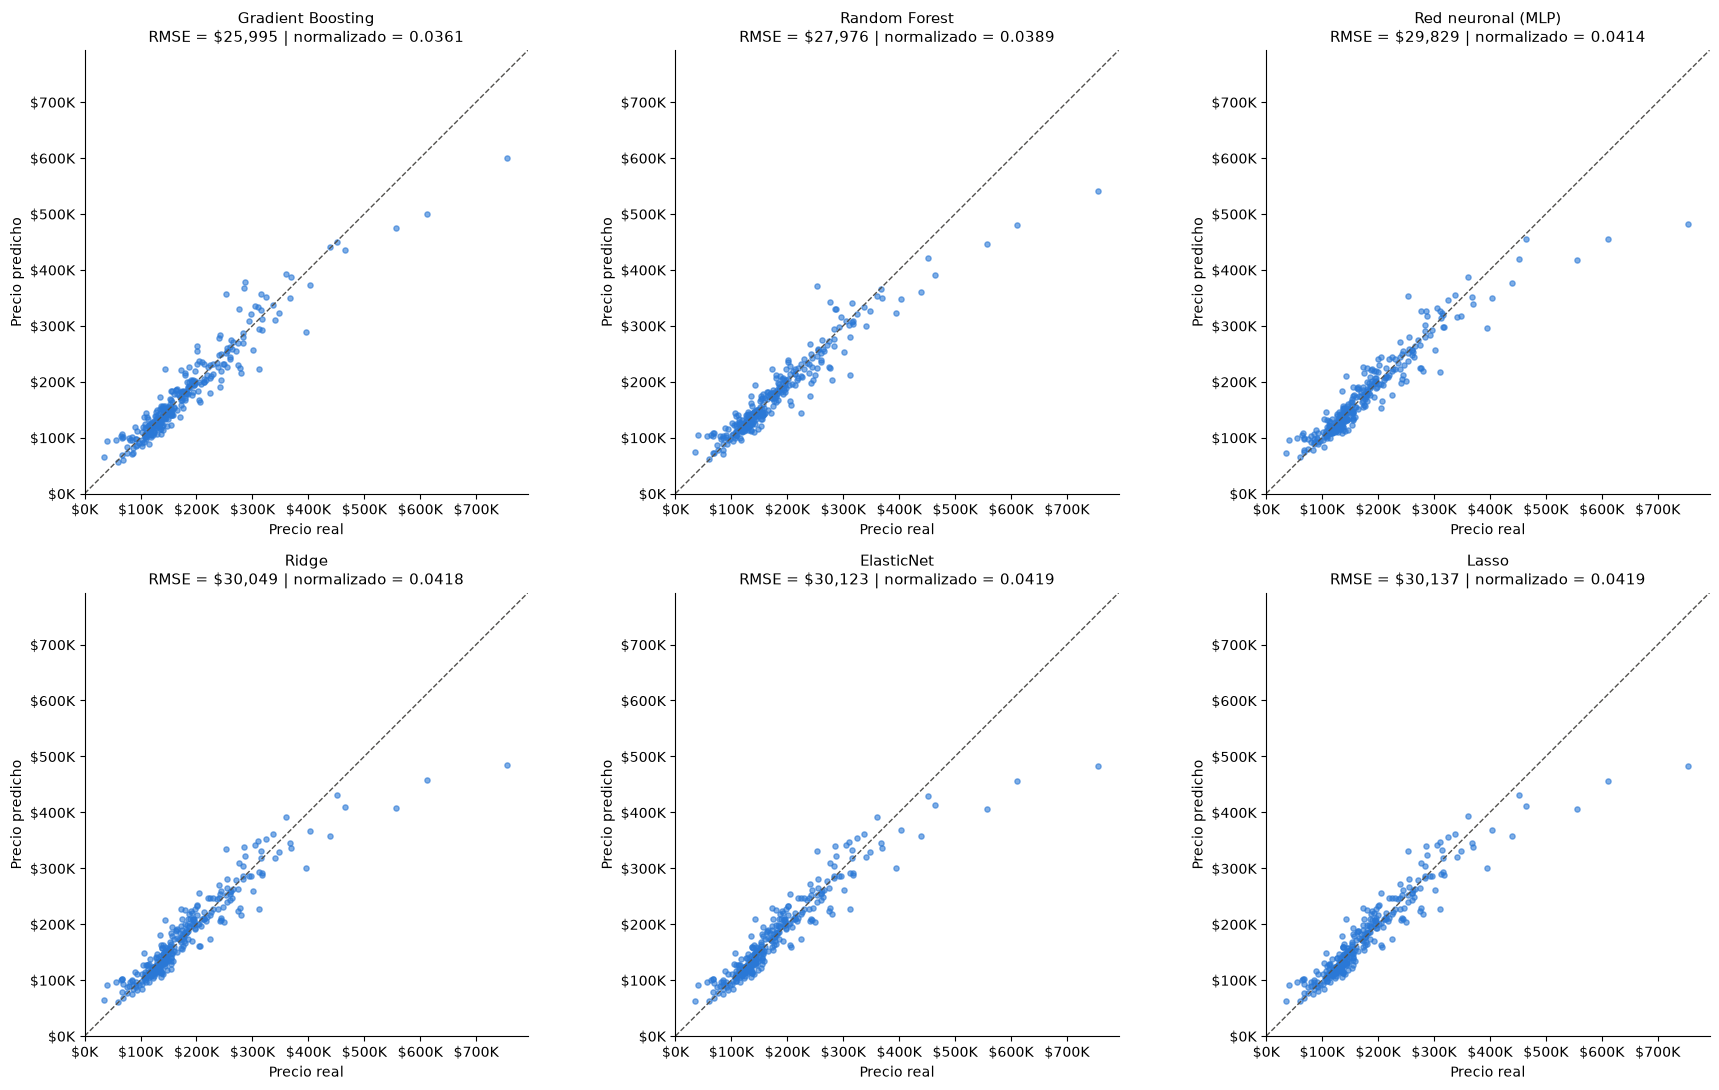

In [9]:
COLOR_SERIE = "#2a78d6"
COLOR_REFERENCIA = "#52514e"
N_COLUMNAS = 3

n_filas = int(np.ceil(len(df_torneo) / N_COLUMNAS))
fig, axes = plt.subplots(n_filas, N_COLUMNAS, figsize=(6 * N_COLUMNAS, 5.5 * n_filas))
axes = axes.flatten()

limite = max(y_val_real.max(), max(pred.max() for pred in predicciones_val.values())) * 1.05
formato_miles = FuncFormatter(lambda valor, _: f"\\${valor / 1000:,.0f}K")

for ax, nombre in zip(axes, df_torneo.index):
    ax.plot([0, limite], [0, limite], color=COLOR_REFERENCIA, linestyle="--", linewidth=1)
    ax.scatter(y_val_real, predicciones_val[nombre], s=14, alpha=0.6, color=COLOR_SERIE)
    ax.set_title(
        f"{nombre}\nRMSE = \\${df_torneo.loc[nombre, 'rmse_real']:,.0f} | "
        f"normalizado = {df_torneo.loc[nombre, 'rmse_normalizado']:.4f}",
        fontsize=11,
    )
    ax.set_xlabel("Precio real")
    ax.set_ylabel("Precio predicho")
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(formato_miles)
    ax.yaxis.set_major_formatter(formato_miles)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(df_torneo):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 10. Almacenamiento del modelo ganador

Se guarda en `models/` el mejor candidato del torneo, tal como fue evaluado: incluye el pipeline completo de ingeniería de características y el modelo, ambos ajustados solo con el conjunto de entrenamiento. Recibe datos con las columnas de `MODEL_FEATURES` y predice en escala logarítmica.

In [10]:
MODELO_GANADOR_FILE = MODELS_DIR / "modelo_ganador.joblib"

nombre_ganador = df_torneo.index[0]
modelo_ganador = busquedas[nombre_ganador].best_estimator_

joblib.dump(modelo_ganador, MODELO_GANADOR_FILE)

print(f"Modelo ganador: {nombre_ganador}")
print(f"RMSE real en validación: {df_torneo.loc[nombre_ganador, 'rmse_real']:,.0f}")
print(f"Guardado en: {MODELO_GANADOR_FILE.name}")

Modelo ganador: Gradient Boosting
RMSE real en validación: 25,995
Guardado en: modelo_ganador.joblib


## 11. Exportación de resultados para visualización

Se exportan a `reports/resultados_torneo.json` las métricas, las 20 configuraciones y los folds de cada modelo, sus predicciones en validación y la forma de sus predicciones sobre `test.csv`. Las predicciones en test solo se usan para evaluar coherencia; no participan en ningún ajuste.

Un modelo se marca como descartado si incumple alguna regla de salida en test: tener nulos o precios menores o iguales a 0, una mediana fuera de ±15 % de la mediana real de `train.csv` o una correlación menor a 0.90 con las predicciones del pipeline de inferencia. Una brecha entrenamiento-CV mayor a 0.05 genera una alerta de sobreajuste, sin descartar el modelo.

In [11]:
import json

from scipy.stats import gaussian_kde

from ejercicio_clases.config import REPORTS_DIR

RESULTADOS_FILE = REPORTS_DIR / "resultados_torneo.json"
PREDICCIONES_FILE = PROCESSED_DATA_DIR / "predicciones_test.csv"

TOLERANCIA_MEDIANA = 0.15
CORRELACION_MINIMA = 0.90
BRECHA_ALERTA = 0.05

X_test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="Id")[MODEL_FEATURES]
predicciones_test = {
    nombre: pd.Series(np.expm1(busqueda.predict(X_test)), index=X_test.index)
    for nombre, busqueda in busquedas.items()
}

# Referencia: predicciones del ganador, que deben coincidir con las del notebook de inferencia
referencia = predicciones_test[nombre_ganador]
if PREDICCIONES_FILE.exists():
    inferencia = pd.read_csv(PREDICCIONES_FILE, index_col="Id")[TARGET]
    assert inferencia.index.equals(referencia.index) and np.allclose(inferencia, referencia)

precios_train = df_train[TARGET]
mediana_train = precios_train.median()
malla = np.linspace(0, 800000, 161)


def valor_simple(valor):
    if isinstance(valor, np.integer):
        return int(valor)
    if isinstance(valor, np.floating):
        return round(float(valor), 6)
    return str(valor) if isinstance(valor, tuple) else valor


def nombres_simples(parametros):
    return {
        clave.split("__")[-1]: valor_simple(valor)
        for clave, valor in parametros.items()
    }


def densidad(valores):
    return [round(float(valor), 12) for valor in gaussian_kde(valores)(malla)]


def resumen(valores):
    return {
        "media": float(valores.mean()),
        "mediana": float(valores.median()),
        "desv": float(valores.std()),
        "min": float(valores.min()),
        "max": float(valores.max()),
        "p05": float(valores.quantile(0.05)),
        "p95": float(valores.quantile(0.95)),
    }


modelos_exportados = []
for nombre in df_torneo.index:
    busqueda = busquedas[nombre]
    resultados = busqueda.cv_results_
    i = busqueda.best_index_
    pred_test = predicciones_test[nombre]

    n_nulos = int(pred_test.isna().sum())
    n_no_positivos = int((pred_test <= 0).sum())
    desvio_mediana = pred_test.median() / mediana_train - 1
    correlacion = pred_test.corr(referencia)

    razones = []
    if n_nulos:
        razones.append(f"{n_nulos} predicciones nulas")
    if n_no_positivos:
        razones.append(f"{n_no_positivos} precios menores o iguales a 0")
    if abs(desvio_mediana) > TOLERANCIA_MEDIANA:
        razones.append(f"mediana {desvio_mediana:+.1%} respecto a train")
    if correlacion < CORRELACION_MINIMA:
        razones.append(f"correlación {correlacion:.3f} con el ganador")

    modelos_exportados.append({
        "nombre": nombre,
        "tipo": "Regresión" if nombre in ("Ridge", "Lasso", "ElasticNet") else ("Red neuronal" if "MLP" in nombre else "Ensamble"),
        "metricas": {**df_torneo.loc[nombre].to_dict(), **df_cv.loc[nombre, ["rmse_log_train_cv", "desv_folds", "brecha_cv"]].to_dict()},
        "mejores_parametros": nombres_simples(busqueda.best_params_),
        "configuraciones": [
            {
                "parametros": nombres_simples(resultados["params"][k]),
                "rmse_cv": float(-resultados["mean_test_score"][k]),
                "desv": float(resultados["std_test_score"][k]),
                "rmse_train": float(-resultados["mean_train_score"][k]),
                "posicion": int(resultados["rank_test_score"][k]),
            }
            for k in range(N_CONFIGURACIONES)
        ],
        "folds_cv": [float(-resultados[f"split{k}_test_score"][i]) for k in range(N_FOLDS)],
        "folds_train": [float(-resultados[f"split{k}_train_score"][i]) for k in range(N_FOLDS)],
        "validacion_predicho": [int(round(valor)) for valor in predicciones_val[nombre]],
        "test": {
            "resumen": resumen(pred_test),
            "densidad": densidad(pred_test),
            "nulos": n_nulos,
            "no_positivos": n_no_positivos,
            "desvio_mediana": float(desvio_mediana),
            "correlacion": float(correlacion),
            "diferencia_media_abs": float((pred_test - referencia).abs().mean()),
        },
        "descartado": bool(razones),
        "razones": razones,
        "alerta_sobreajuste": bool(df_cv.loc[nombre, "brecha_cv"] > BRECHA_ALERTA),
    })

salida = {
    "ganador": nombre_ganador,
    "parametros": {
        "n_folds": N_FOLDS,
        "n_configuraciones": N_CONFIGURACIONES,
        "registros_entrenamiento": len(X_train),
        "registros_validacion": len(X_val),
        "registros_test": len(X_test),
        "rango_validacion": float(rango_val),
        "tolerancia_mediana": TOLERANCIA_MEDIANA,
        "correlacion_minima": CORRELACION_MINIMA,
        "brecha_alerta": BRECHA_ALERTA,
    },
    "malla": [float(valor) for valor in malla],
    "train": {"resumen": resumen(precios_train), "densidad": densidad(precios_train)},
    "validacion_real": [int(round(valor)) for valor in y_val_real],
    "modelos": modelos_exportados,
}

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULTADOS_FILE, "w", encoding="utf-8") as archivo:
    json.dump(salida, archivo, ensure_ascii=False)

pd.DataFrame([
    {
        "modelo": modelo["nombre"],
        "mediana_test": round(modelo["test"]["resumen"]["mediana"]),
        "desvio_mediana": round(modelo["test"]["desvio_mediana"], 4),
        "correlacion_ganador": round(modelo["test"]["correlacion"], 4),
        "descartado": modelo["descartado"],
        "alerta_sobreajuste": modelo["alerta_sobreajuste"],
    }
    for modelo in modelos_exportados
]).set_index("modelo")

,mediana_test,desvio_mediana,correlacion_ganador,descartado,alerta_sobreajuste
modelo,,,,,
Gradient Boosting,157103,-0.0362,1.0000,False,False
Random Forest,156286,-0.0412,0.9891,False,True
Red neuronal (MLP),155913,-0.0435,0.9854,False,False
Ridge,158759,-0.0260,0.9860,False,False
ElasticNet,158644,-0.0267,0.9861,False,False
Lasso,158690,-0.0264,0.9860,False,False


## 12. Configuración de MLflow

Se conecta el notebook al servidor de tracking local (SQLite, `mlflow.db` en la raíz del proyecto) y se selecciona el experimento de entrenamiento. Los artefactos (modelos y gráficas) se guardan en `MLFLOW_ARTIFACTS_DIR`, una ruta corta fuera del proyecto, porque la ruta del proyecto supera el límite de longitud de Windows.

In [12]:
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
from skops.io import dumps, get_untrusted_types
from sklearn.compose import ColumnTransformer

from ejercicio_clases.config import MLFLOW_ARTIFACTS_DIR, MLFLOW_REGISTERED_MODEL, MLFLOW_TRACKING_URI

EXPERIMENTO_ENTRENAMIENTO = "house_pricing_entrenamiento"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experimento = mlflow.get_experiment_by_name(EXPERIMENTO_ENTRENAMIENTO)
id_experimento = (
    experimento.experiment_id
    if experimento
    else mlflow.create_experiment(EXPERIMENTO_ENTRENAMIENTO, artifact_location=MLFLOW_ARTIFACTS_DIR.as_uri())
)
mlflow.set_experiment(experiment_id=id_experimento)

print(f"Experimento: {EXPERIMENTO_ENTRENAMIENTO} (id {id_experimento})")
print(f"Artefactos en: {mlflow.get_experiment(id_experimento).artifact_location}")

C:\Users\aillu\AppData\Local\anaconda3\envs\env_house_pricing_aillu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/10 19:48:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/10 19:48:31 INFO mlflow.store.db.utils: Updating database tables


Experimento: house_pricing_entrenamiento (id 1)
Artefactos en: file:///C:/Users/aillu/mlflow/house_pricing


## 13. Pipelines de inferencia por modelo

Para cada modelo se arma el mismo flujo del pipeline de inferencia: selección de `MODEL_FEATURES` desde los datos crudos, ingeniería de características, modelo y conversión a dólares con `TransformedTargetRegressor`. Se ajusta con el mismo conjunto de entrenamiento y los mejores hiperparámetros de cada búsqueda. La celda comprueba que cada pipeline reproduzca exactamente las predicciones del torneo en validación.

In [13]:
X_crudo = df_train.drop(columns=TARGET)
X_train_crudo = X_crudo.loc[X_train.index]
X_val_crudo = X_crudo.loc[X_val.index]
y_train_real = df_train.loc[X_train.index, TARGET]


def crear_pipeline_inferencia(busqueda):
    seleccion_variables = ColumnTransformer(
        [("model_features", "passthrough", MODEL_FEATURES)],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    mejor = busqueda.best_estimator_
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("seleccion", seleccion_variables),
            ("fe", clone(mejor.named_steps["fe"])),
            ("modelo", clone(mejor.named_steps["modelo"])),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False,
    )


pipelines_inferencia = {}
for nombre, busqueda in busquedas.items():
    pipeline = crear_pipeline_inferencia(busqueda).fit(X_train_crudo, y_train_real)
    assert np.allclose(pipeline.predict(X_val_crudo), predicciones_val[nombre]), nombre
    pipelines_inferencia[nombre] = pipeline

print(f"Pipelines verificados: {list(pipelines_inferencia)}")

Pipelines verificados: ['Ridge', 'Lasso', 'ElasticNet', 'Random Forest', 'Gradient Boosting', 'Red neuronal (MLP)']


## 14. Registro del entrenamiento en MLflow

Se crea un run por modelo con:

- **Parámetros:** los del proceso (folds, configuraciones, semilla, tamaños) y los mejores hiperparámetros.
- **Métricas:** CV, validación, brechas de sobreajuste y el RMSE de cada fold como serie.
- **Artefactos:** la gráfica real vs. predicho, la tabla de las 20 configuraciones, la lista de variables y el pipeline de inferencia.

Cada configuración probada se registra como un run hijo con sus hiperparámetros y métricas.

El esquema de entrada declara las columnas numéricas como decimales, porque en producción pueden llegar con faltantes. El pipeline se guarda en formato `skops`, declarando como confiables los tipos de `feature-engine` y de los árboles de scikit-learn, ya que el modelo se genera en este mismo notebook.

In [14]:
columnas_enteras = X_train_crudo.select_dtypes(include="integer").columns
ejemplo_entrada = X_train_crudo.astype({columna: "float64" for columna in columnas_enteras})

parametros_proceso = {
    "n_folds": N_FOLDS,
    "n_configuraciones": N_CONFIGURACIONES,
    "semilla": SEMILLA,
    "tamano_validacion": TAMANO_VALIDACION,
    "registros_entrenamiento": len(X_train),
    "registros_validacion": len(X_val),
    "n_features": len(MODEL_FEATURES),
    "metrica_busqueda": "rmse_log",
    "target": "log1p(SalePrice)",
}
estado_modelos = {modelo["nombre"]: modelo for modelo in modelos_exportados}


def grafica_real_vs_predicho(nombre):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, limite], [0, limite], color=COLOR_REFERENCIA, linestyle="--", linewidth=1)
    ax.scatter(y_val_real, predicciones_val[nombre], s=14, alpha=0.6, color=COLOR_SERIE)
    ax.set_title(f"{nombre} | RMSE = {df_torneo.loc[nombre, 'rmse_real']:,.0f}")
    ax.set_xlabel("Precio real")
    ax.set_ylabel("Precio predicho")
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.xaxis.set_major_formatter(formato_miles)
    ax.yaxis.set_major_formatter(formato_miles)
    ax.spines[["top", "right"]].set_visible(False)
    plt.close(fig)
    return fig


runs_modelos = {}
for posicion, nombre in enumerate(df_torneo.index, start=1):
    busqueda = busquedas[nombre]
    resultados = busqueda.cv_results_
    i = busqueda.best_index_
    pipeline = pipelines_inferencia[nombre]

    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({
            "tipo": estado_modelos[nombre]["tipo"],
            "posicion_torneo": posicion,
            "alerta_sobreajuste": estado_modelos[nombre]["alerta_sobreajuste"],
            "descartado": estado_modelos[nombre]["descartado"],
        })
        mlflow.log_params(parametros_proceso)
        mlflow.log_params({clave.split("__")[-1]: valor for clave, valor in busqueda.best_params_.items()})
        mlflow.log_metrics({
            **df_torneo.loc[nombre].to_dict(),
            **df_cv.loc[nombre].to_dict(),
            "tiempo_ajuste_medio_s": resultados["mean_fit_time"][i],
        })
        for k in range(N_FOLDS):
            mlflow.log_metric("rmse_log_fold_cv", -resultados[f"split{k}_test_score"][i], step=k + 1)
            mlflow.log_metric("rmse_log_fold_train", -resultados[f"split{k}_train_score"][i], step=k + 1)

        mlflow.log_figure(grafica_real_vs_predicho(nombre), "real_vs_predicho_validacion.png")
        mlflow.log_text("\n".join(MODEL_FEATURES), "model_features.txt")
        mlflow.log_table(
            pd.DataFrame(resultados["params"]).astype(str).assign(
                rmse_cv=-resultados["mean_test_score"],
                desv=resultados["std_test_score"],
                rmse_train=-resultados["mean_train_score"],
                posicion=resultados["rank_test_score"],
            ),
            "configuraciones.json",
        )

        for k in range(N_CONFIGURACIONES):
            with mlflow.start_run(run_name=f"{nombre} | configuración {resultados['rank_test_score'][k]}", nested=True):
                mlflow.set_tag("mejor_configuracion", k == i)
                mlflow.log_params({clave.split("__")[-1]: valor for clave, valor in resultados["params"][k].items()})
                mlflow.log_metrics({
                    "rmse_log_cv": -resultados["mean_test_score"][k],
                    "desv_folds": resultados["std_test_score"][k],
                    "rmse_log_train_cv": -resultados["mean_train_score"][k],
                    "posicion": resultados["rank_test_score"][k],
                })

        runs_modelos[nombre] = mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="pipeline_inferencia",
            signature=infer_signature(ejemplo_entrada, pipeline.predict(ejemplo_entrada)),
            input_example=ejemplo_entrada.head(5),
            skops_trusted_types=get_untrusted_types(data=dumps(pipeline)),
        )

    print(f"{posicion}. {nombre}: run {runs_modelos[nombre].run_id}")

1. Gradient Boosting: run 0d825230dab34811be826746e0f5f2f4


2. Random Forest: run a609361fb01a40feb19857edc1d4341f


3. Red neuronal (MLP): run 862c056326da44dbac5b661501bbcf59


4. Ridge: run ae7f42879332482ba66efe3f72e4ef25


5. ElasticNet: run 2fb3ef81bf2d474c91e53bec01f46958


6. Lasso: run fcab184087924009be184870898ee834


## 15. Registro de champion y challengers

Los modelos no descartados se ordenan por RMSE real en validación. El primero se registra con el alias `champion` y los dos siguientes como `challenger_1` y `challenger_2`, todos como versiones del modelo registrado `house_pricing`. Cada versión lleva etiquetas con el nombre del modelo, su RMSE real y la alerta de sobreajuste. Al reejecutar el notebook se crean versiones nuevas y los alias se mueven a ellas.

In [15]:
ALIAS = ["champion", "challenger_1", "challenger_2"]

candidatos = [nombre for nombre in df_torneo.index if not estado_modelos[nombre]["descartado"]]
cliente = MlflowClient()

registro = []
for alias, nombre in zip(ALIAS, candidatos):
    version = mlflow.register_model(runs_modelos[nombre].model_uri, MLFLOW_REGISTERED_MODEL)
    cliente.set_registered_model_alias(MLFLOW_REGISTERED_MODEL, alias, version.version)
    cliente.set_model_version_tag(MLFLOW_REGISTERED_MODEL, version.version, "modelo", nombre)
    cliente.set_model_version_tag(MLFLOW_REGISTERED_MODEL, version.version, "rmse_real", f"{df_torneo.loc[nombre, 'rmse_real']:.0f}")
    cliente.set_model_version_tag(MLFLOW_REGISTERED_MODEL, version.version, "alerta_sobreajuste", str(estado_modelos[nombre]["alerta_sobreajuste"]))
    cliente.update_model_version(
        MLFLOW_REGISTERED_MODEL,
        version.version,
        description=f"{nombre}: pipeline de inferencia (datos crudos a dólares). RMSE real en validación: {df_torneo.loc[nombre, 'rmse_real']:,.0f}.",
    )
    registro.append({"alias": alias, "modelo": nombre, "version": version.version, "rmse_real": round(df_torneo.loc[nombre, "rmse_real"])})

assert cliente.get_model_version_by_alias(MLFLOW_REGISTERED_MODEL, "champion").tags["modelo"] == nombre_ganador
pd.DataFrame(registro).set_index("alias")

Successfully registered model 'house_pricing'.
Created version '1' of model 'house_pricing'.


Registered model 'house_pricing' already exists. Creating a new version of this model...
Created version '2' of model 'house_pricing'.
Registered model 'house_pricing' already exists. Creating a new version of this model...


Created version '3' of model 'house_pricing'.


,modelo,version,rmse_real
alias,,,
champion,Gradient Boosting,1,25995
challenger_1,Random Forest,2,27976
challenger_2,Red neuronal (MLP),3,29829
